# Công việc 9 — xem biểu đồ đánh giá mô hình

Notebook này đọc `data/task9/model/metrics.json` và tạo các biểu đồ SVG cho báo cáo. Các điểm validation hiện tại so sánh mô hình với nhãn LLM, không phải test gold do người gán.

Chạy notebook từ thư mục gốc repo. Cần Python và IPython/Jupyter; phần tạo hình chỉ dùng thư viện chuẩn Python.

In [1]:
from pathlib import Path
import sys
from IPython.display import SVG, display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'data/task9/model/metrics.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook khi dữ liệu task9/model/metrics.json có trong workspace')
TASK9_CODE = ROOT / 'src/processing/task9'
sys.path.insert(0, str(TASK9_CODE))
from make_report_figures import make_figures

figures = make_figures(ROOT / 'data/task9/model/metrics.json', ROOT / 'docs/reports/task9/figures')
print('Đã tạo:', *[p.relative_to(ROOT) for p in figures], sep='\n- ')

Đã tạo:
- docs/reports/task9/figures/confusion_matrix.svg
- docs/reports/task9/figures/aspect_macro_f1.svg
- docs/reports/task9/figures/class_distribution.svg
- docs/reports/task9/figures/learning_curve.svg


confusion_matrix.svg


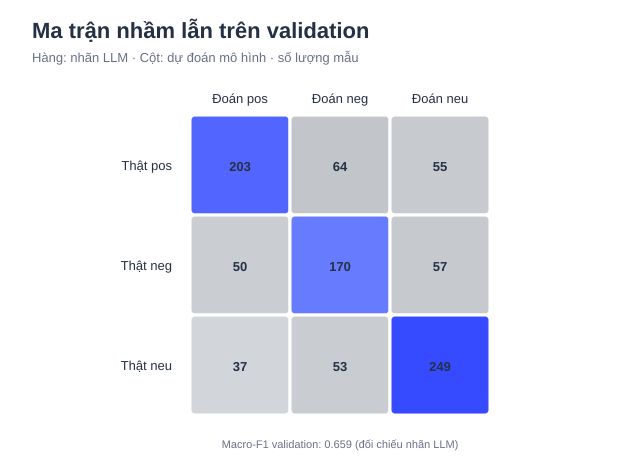

aspect_macro_f1.svg


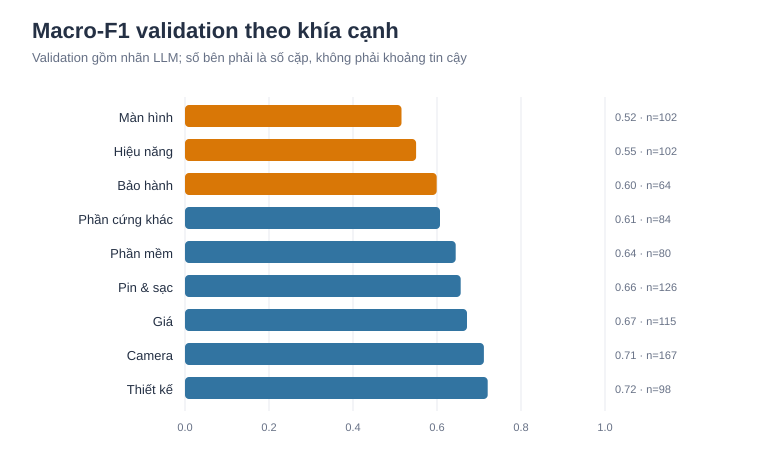

class_distribution.svg


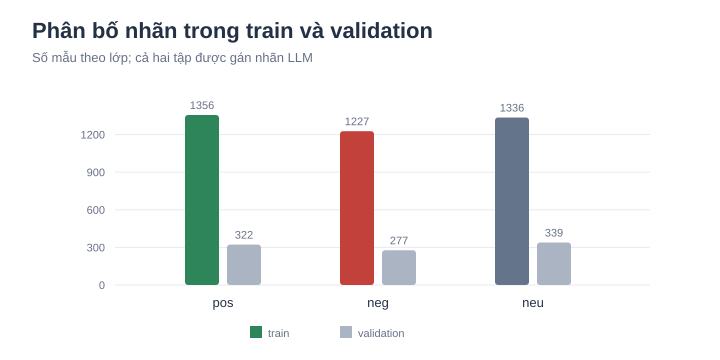

learning_curve.svg


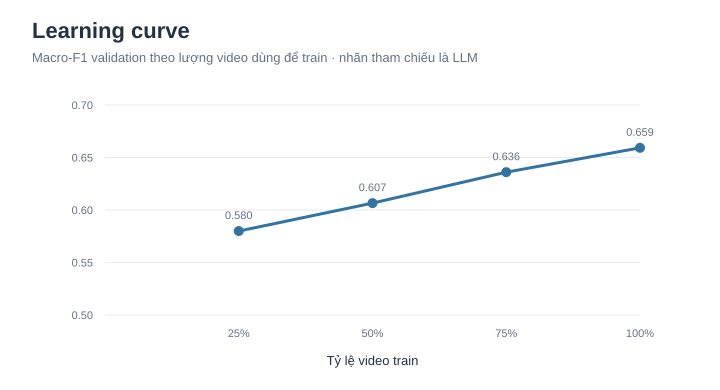

In [2]:
for figure in figures:
    print(figure.name)
    display(SVG(filename=str(figure)))